# Subgroup performance analysis

This notebook evaluates whether model performance is consistent across clinically relevant subgroups on the temporal test set. It examines discrimination, probabilistic accuracy, calibration-related error, and fixed-threshold classification performance.

Subgroups are defined in `analysis.yaml` and may contain one condition or several combined conditions using `logic: all` or `logic: any`. Unknown outcomes are excluded from performance calculations, but they are reported in the subgroup-size table.

The principal figures are small-multiple heatmaps. Rows represent subgroups, columns represent models, and each panel represents one metric. This is clearer than placing all metrics on one axis because AUROC/AUPRC, Brier score, and threshold metrics have different interpretations. Cell annotations show the estimate and bootstrap confidence interval where available; subgroup size and event count are shown in the row labels.

## Interpretation and limitations

A subgroup result is not evidence that a feature causes the outcome or that the model is clinically fair. It describes predictive performance within the observed subgroup. Small subgroups, particularly those with few ESBL events, can produce very imprecise estimates. Always inspect `n` and `n_events` alongside the metrics.

Sensitivity, specificity, PPV, and NPV use the configured threshold. The threshold is not re-optimised separately within each subgroup. This preserves a clinically consistent operating point.

In [33]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
plt.ioff()

from icare_risk.subgroups import (
    load_subgroup_definitions,
    subgroup_sizes,
    evaluate_subgroups,
)
from icare_risk.evaluation.plots import (
    plot_subgroup_performance_dashboard,
    plot_subgroup_performance_forest,
    save_figure,
)

## 1. Load configuration and prediction table

The prediction table is the central analysis table: it should contain one row per admission, the target, subgroup variables, the split label, and one probability column per fitted model. This notebook does not retrain models.

In [23]:
CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as handle:
    config = yaml.safe_load(handle)

prediction_path = (
    Path(config['outputs']['prediction_directory'])
    / 'admission_predictions.parquet'
)
if not prediction_path.exists():
    raise FileNotFoundError(
        f'Prediction table not found: {prediction_path}. '
        'Run 04_generate_predictions.ipynb first.'
    )

predictions = pd.read_parquet(prediction_path)
target = config['columns']['target']
target_mapping = config.get('target_mapping', {})
analysis_config = config.get('analysis', {})
threshold = analysis_config.get('evaluation_threshold', 0.5)
prediction_columns = [column for column in predictions.columns if column.endswith('_prob')]

print(f'Configuration: {CONFIG_PATH}')
print(f'Prediction table: {prediction_path}')
print(f'Rows: {len(predictions):,}; columns: {len(predictions.columns):,}')
print(f'Target: {target}')
print(f'Model probability columns: {len(prediction_columns)}')
print(f'Fixed classification threshold: {threshold}')
if 'split' in predictions.columns:
    print('Rows by split:')
    display(predictions['split'].value_counts(dropna=False).rename_axis('split').to_frame('n'))

definitions = load_subgroup_definitions(config.get('subgroups', {}))
if not definitions:
    raise ValueError('No subgroups configured in analysis.yaml')
print(f'Configured subgroups: {len(definitions)}')

Configuration: ../src/icare_risk/config/icare/analysis.yaml
Prediction table: results/predictions/admission_predictions.parquet
Rows: 10,000; columns: 193
Target: esbl_label_test
Model probability columns: 6
Fixed classification threshold: 0.5
Rows by split:


,n
split,
train,6054
test,2483
validation,1463


Configured subgroups: 12


## 2. Restrict analysis to the temporal test set

The test set is used here because subgroup performance should be reported on admissions that were not used to fit the final models. If the prediction table has no `split` column, the notebook stops rather than silently evaluating the wrong cohort.

In [24]:
if 'split' not in predictions.columns:
    raise KeyError("Prediction table must contain a 'split' column.")
test_mask = predictions['split'].eq('test')
test_predictions = predictions.loc[test_mask].copy()
if test_predictions.empty:
    raise ValueError('The temporal test set is empty.')

print(f'Temporal test-set rows: {len(test_predictions):,}')
if target in test_predictions:
    print('Target values in test set:')
    display(test_predictions[target].value_counts(dropna=False).rename_axis(target).to_frame('n'))

size_table = subgroup_sizes(
    test_predictions,
    definitions,
    target_column=target,
    target_mapping=target_mapping,
)
display(size_table)

Temporal test-set rows: 2,483
Target values in test set:


,n
esbl_label_test,
0,1990
1,493


,subgroup,n,n_events,n_non_events,n_unknown
0,age_under_65,1479,297,1182,0
1,age_65_or_over,1004,196,808,0
2,female,619,132,487,0
3,male,610,130,480,0
4,diabetes,2015,407,1608,0
5,renal_disease,65,18,47,0
6,cancer,2,0,2,0
7,intensive_care,0,0,0,0
8,medicine,634,126,508,0
9,surgery,619,112,507,0


## 3. Evaluate every model within every subgroup

Each subgroup/model pair receives point estimates and bootstrap confidence intervals. This can be computationally expensive: the number of evaluations is `number of subgroups × number of models`, and each evaluation performs the configured number of bootstrap resamples.

In [8]:
bootstrap_iterations = analysis_config.get('bootstrap_iterations', 1000)
confidence_level = analysis_config.get('confidence_level', 0.95)
print(f'Evaluations: {len(definitions)} subgroups × {len(prediction_columns)} models')
print(f'Bootstrap resamples per evaluation: {bootstrap_iterations:,}')

evaluation = evaluate_subgroups(
    test_predictions,
    definitions,
    target_column=target,
    prediction_columns=prediction_columns,
    threshold=threshold,
    target_mapping=target_mapping,
    n_bootstraps=100,
    ci=confidence_level,
    verbose=True,
    progress_every=1,
)

display(evaluation.head(20))
print(f'Result rows: {len(evaluation):,}')

# .. note: SAVE CSS and load in next, so no need to execute.

Evaluations: 12 subgroups × 6 models
Bootstrap resamples per evaluation: 1,000
Starting subgroup evaluation: 2,483 rows, 12 subgroups, 6 models, 72 evaluations, 100 bootstraps each.
Subgroup 'age_under_65': n=1,479
  [1/72] age_under_65 / lr_kim_components_prob: 1.8s; elapsed=1.8s, ETA=130.3s
  [2/72] age_under_65 / lr_all_score_values_prob: 1.3s; elapsed=3.1s, ETA=109.6s
  [3/72] age_under_65 / lr_clinical_baseline_prob: 1.4s; elapsed=4.5s, ETA=103.3s
  [4/72] age_under_65 / xgb_kim_components_prob: 1.4s; elapsed=5.9s, ETA=99.8s
  [5/72] age_under_65 / xgb_all_score_values_prob: 1.3s; elapsed=7.2s, ETA=96.1s
  [6/72] age_under_65 / xgb_clinical_baseline_prob: 1.3s; elapsed=8.5s, ETA=93.2s
Finished subgroup 'age_under_65' in 8.5s.
Subgroup 'age_65_or_over': n=1,004
  [7/72] age_65_or_over / lr_kim_components_prob: 1.3s; elapsed=9.7s, ETA=90.4s
  [8/72] age_65_or_over / lr_all_score_values_prob: 1.2s; elapsed=11.0s, ETA=87.7s
  [9/72] age_65_or_over / lr_clinical_baseline_prob: 1.3s; el

,subgroup,subgroup_column,subgroup_operator,subgroup_value,model,prediction_column,n,n_events,event_rate,auroc,...,npv_ci_lower,npv_ci_upper,accuracy_ci_lower,accuracy_ci_upper,balanced_accuracy_ci_lower,balanced_accuracy_ci_upper,f1_ci_lower,f1_ci_upper,n_bootstraps_requested,n_bootstraps_valid
0,age_under_65,AGE_AT_ADMISSION,<,65,lr_kim_components,lr_kim_components_prob,1479,297,0.200811,0.498651,...,0.780391,0.817184,0.715991,0.753567,0.483235,0.519264,0.097605,0.183443,100.0,100.0
1,age_under_65,AGE_AT_ADMISSION,<,65,lr_all_score_values,lr_all_score_values_prob,1479,297,0.200811,0.514602,...,0.780493,0.817464,0.714317,0.749510,0.483350,0.518092,0.100012,0.182838,100.0,100.0
2,age_under_65,AGE_AT_ADMISSION,<,65,lr_clinical_baseline,lr_clinical_baseline_prob,1479,297,0.200811,0.539230,...,0.786011,0.836866,0.519270,0.575744,0.491200,0.556189,0.262213,0.336033,100.0,100.0
3,age_under_65,AGE_AT_ADMISSION,<,65,xgb_kim_components,xgb_kim_components_prob,1479,297,0.200811,0.498651,...,0.779547,0.815095,0.779547,0.815095,0.500000,0.500000,0.000000,0.000000,100.0,100.0
4,age_under_65,AGE_AT_ADMISSION,<,65,xgb_all_score_values,xgb_all_score_values_prob,1479,297,0.200811,0.498590,...,0.779547,0.815095,0.779547,0.815095,0.500000,0.500000,0.000000,0.000000,100.0,100.0
5,age_under_65,AGE_AT_ADMISSION,<,65,xgb_clinical_baseline,xgb_clinical_baseline_prob,1479,297,0.200811,0.534046,...,0.779547,0.815095,0.779547,0.815095,0.500000,0.500000,0.000000,0.000000,100.0,100.0
6,age_65_or_over,AGE_AT_ADMISSION,>=,65,lr_kim_components,lr_kim_components_prob,1004,196,0.195219,0.502662,...,0.774687,0.825773,0.705603,0.756499,0.483946,0.529394,0.114334,0.208610,100.0,100.0
7,age_65_or_over,AGE_AT_ADMISSION,>=,65,lr_all_score_values,lr_all_score_values_prob,1004,196,0.195219,0.533359,...,0.772203,0.825505,0.663347,0.720642,0.477272,0.535597,0.148144,0.250057,100.0,100.0
8,age_65_or_over,AGE_AT_ADMISSION,>=,65,lr_clinical_baseline,lr_clinical_baseline_prob,1004,196,0.195219,0.502485,...,0.768639,0.832108,0.450149,0.511529,0.466230,0.540991,0.256324,0.337798,100.0,100.0
9,age_65_or_over,AGE_AT_ADMISSION,>=,65,xgb_kim_components,xgb_kim_components_prob,1004,196,0.195219,0.502662,...,0.776843,0.823232,0.776843,0.823232,0.500000,0.500000,0.000000,0.000000,100.0,100.0


Result rows: 72


## 4. Publication-style performance dashboards

The figures below separate metric families rather than mixing all metrics in one axis. The discrimination/calibration figure shows AUROC, AUPRC, and Brier score. The threshold figure shows sensitivity, specificity, PPV, and NPV at the same fixed threshold for every subgroup.

Cells with fewer than the configured minimum number of admissions or events are marked unavailable. This prevents a visually impressive heatmap from implying precision where the data are sparse. Adjust these thresholds for exploratory work, but report the final values.

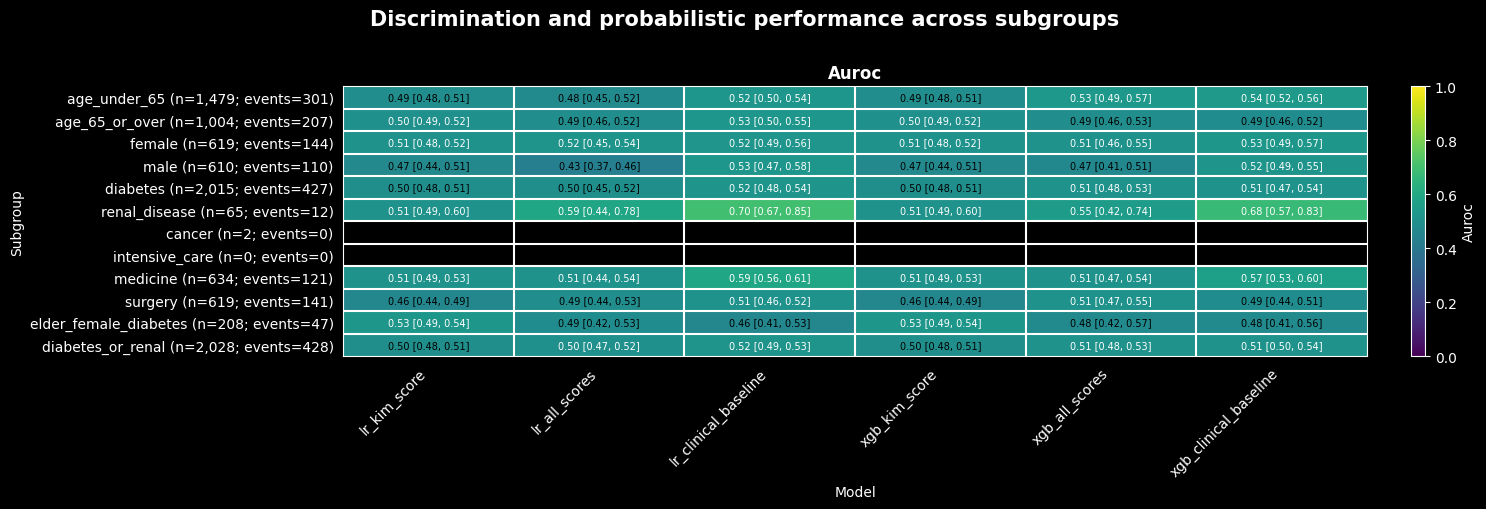

In [41]:
minimum_n = config.get('subgroup_analysis', {}).get('minimum_n', 50)
minimum_events = config.get('subgroup_analysis', {}).get('minimum_events', 10)

figure_discrimination = plot_subgroup_performance_dashboard(
    evaluation,
    metrics=['auroc'],
    title='Discrimination and probabilistic performance across subgroups',
    minimum_n=minimum_n,
    minimum_events=minimum_events,
    show_confidence_intervals=True,
    figsize=(15, 5)
)
display(figure_discrimination)

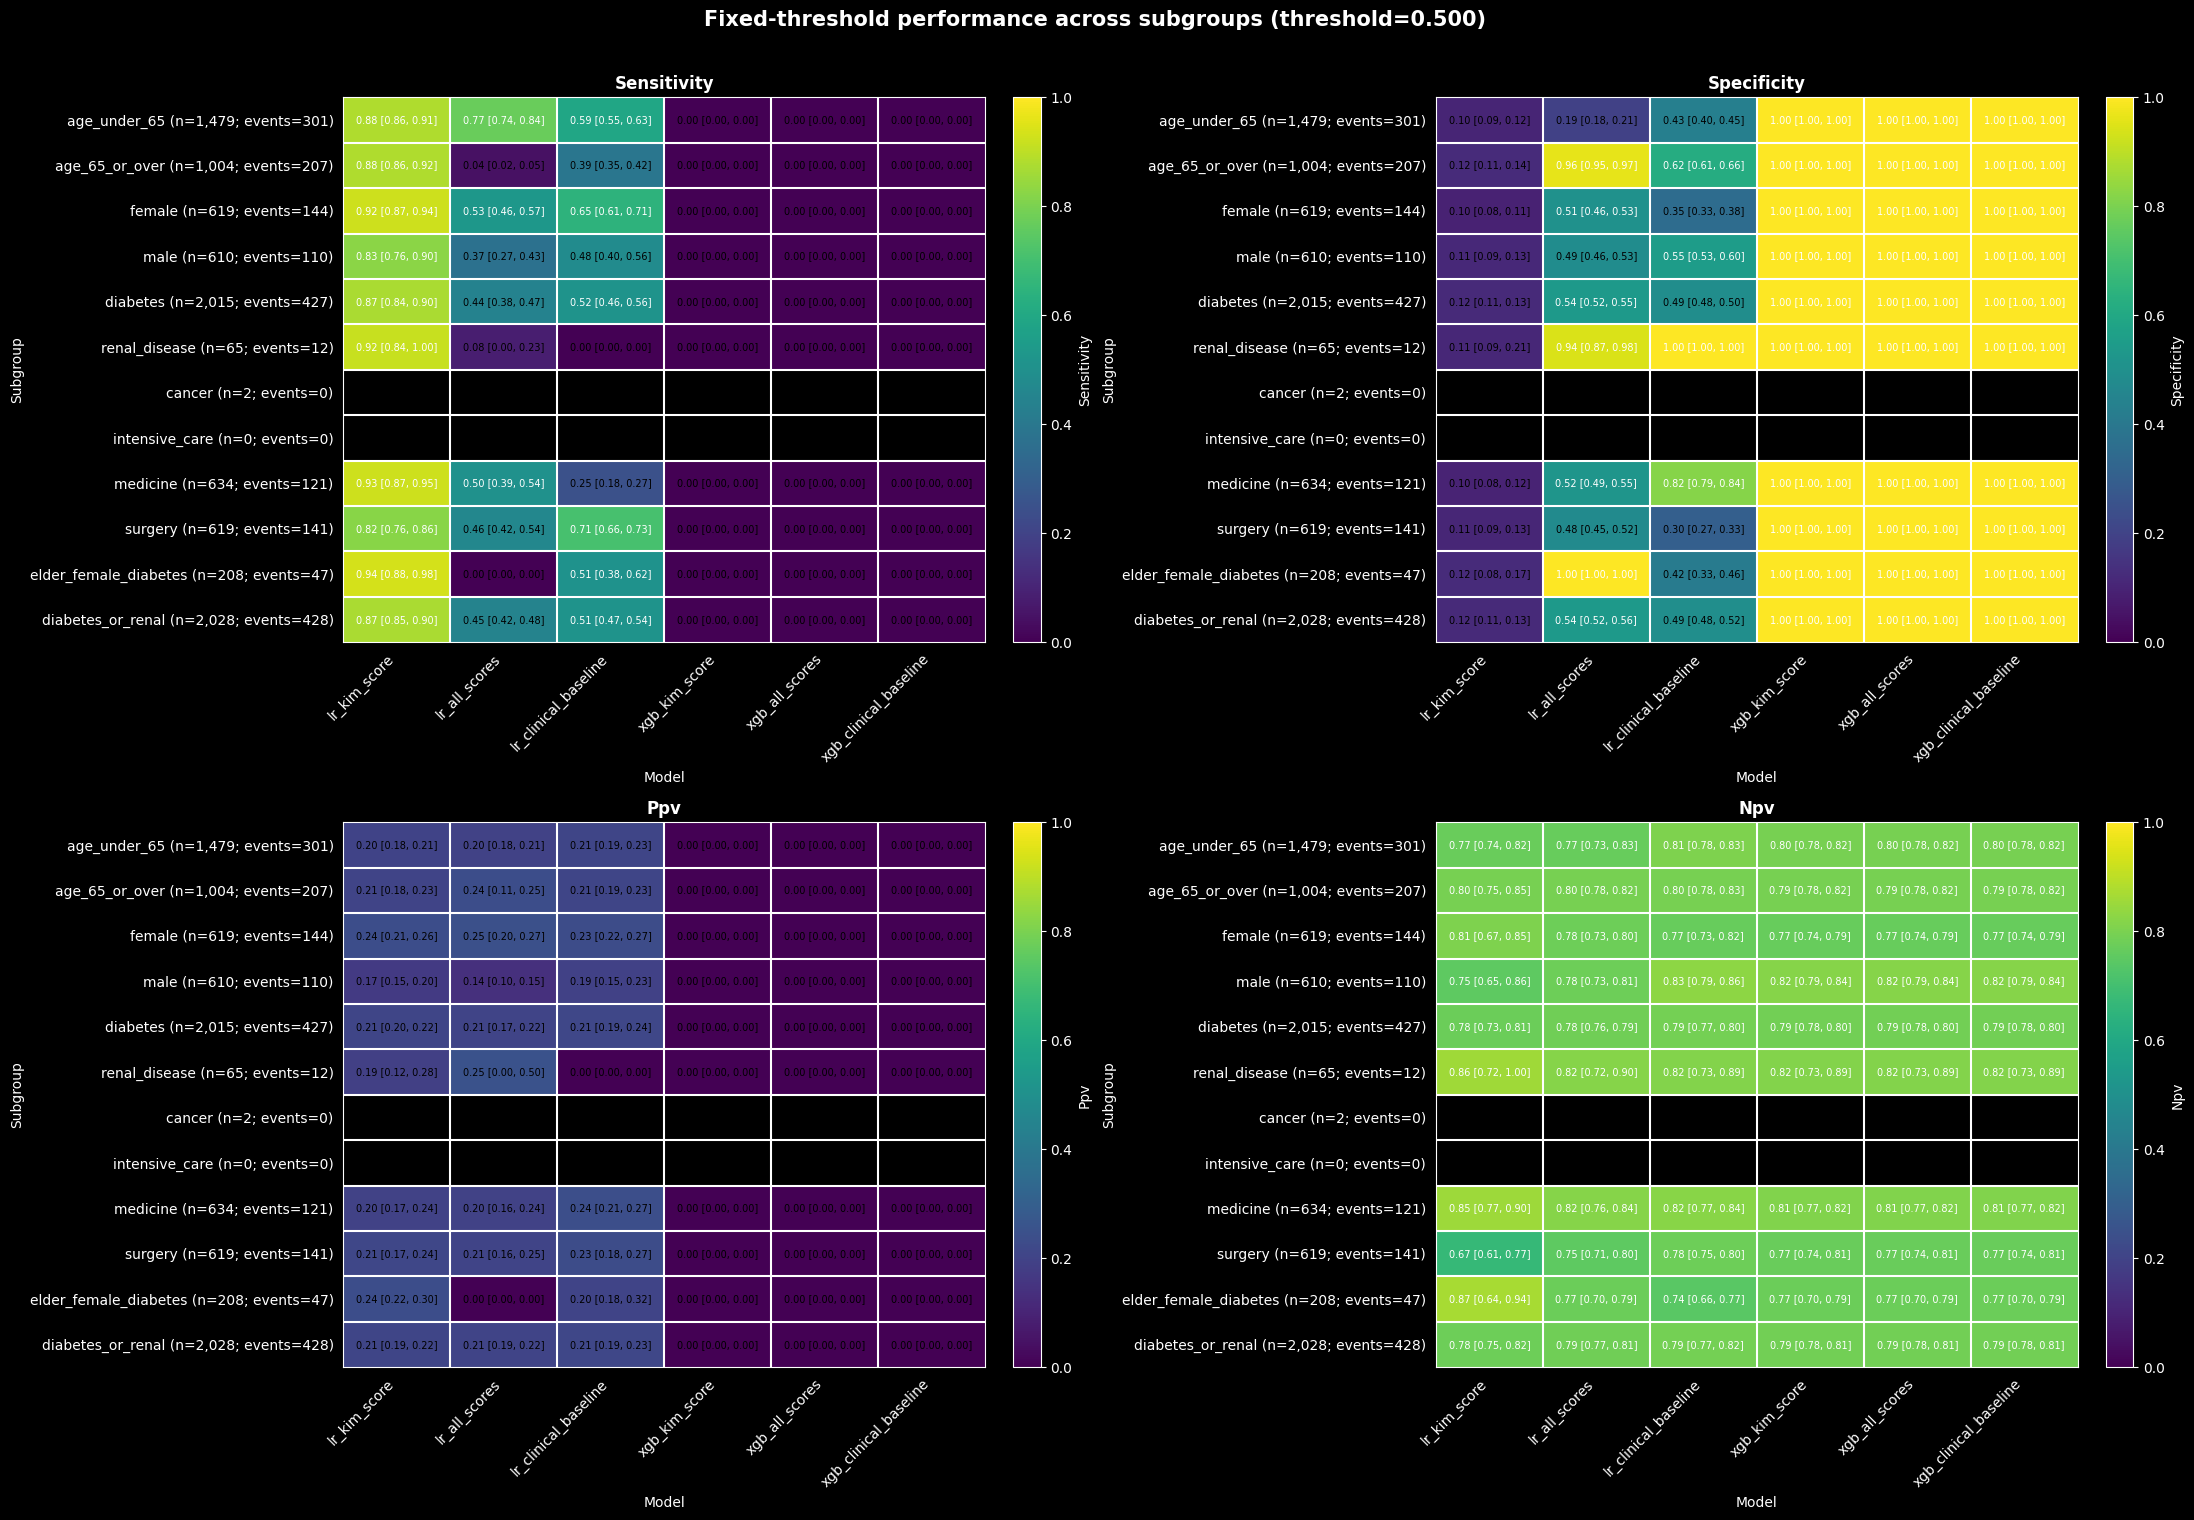

In [40]:
figure_threshold = plot_subgroup_performance_dashboard(
    evaluation,
    metrics=['sensitivity', 'specificity', 'ppv', 'npv'],
    title=f'Fixed-threshold performance across subgroups (threshold={threshold:.3f})',
    minimum_n=minimum_n,
    minimum_events=minimum_events,
    show_confidence_intervals=True,
    figsize=(22,15)
)
display(figure_threshold)

## 5. Optional forest plot for a selected model

The heatmaps compare many models at once. A forest plot is better when the focus is one candidate model and the question is whether performance varies across subgroups.

Models available in subgroup results:
  - lr_all_scores
  - lr_clinical_baseline
  - lr_kim_score
  - xgb_all_scores
  - xgb_clinical_baseline
  - xgb_kim_score


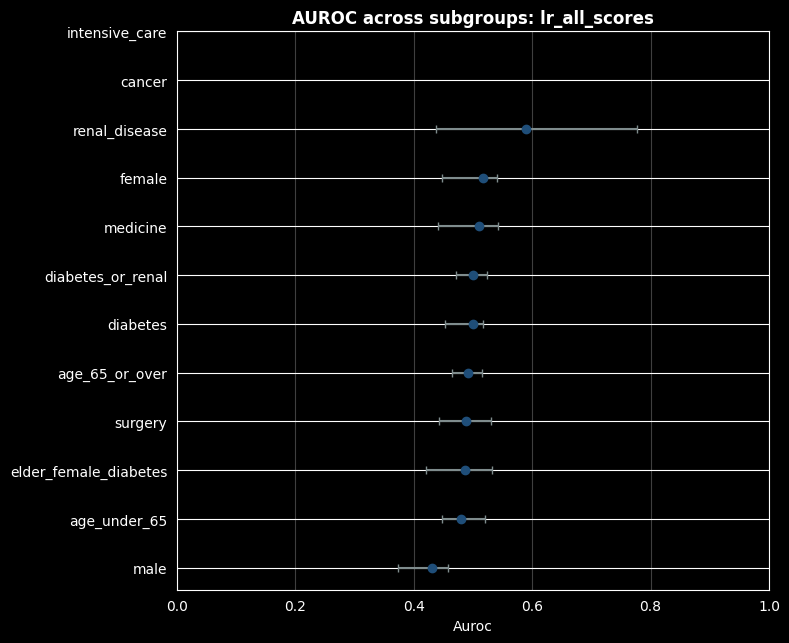

In [39]:
if evaluation.empty or "model" not in evaluation.columns:
    raise ValueError("No subgroup evaluation results are available.")

available_models = sorted(
    evaluation["model"].dropna().astype(str).unique()
)

print("Models available in subgroup results:")
for name in available_models:
    print(f"  - {name}")

selected_model = available_models[0]

figure_forest = plot_subgroup_performance_forest(
    results=evaluation,
    metric="auroc",
    model_name=selected_model,
    title=f"AUROC across subgroups: {selected_model}",
)

display(figure_forest)

## 6. Save tables and figures

Figures are created once, displayed above, and saved below using the same Matplotlib objects. They are not redrawn.

In [32]:
output_dir = Path(config['outputs'].get('subgroup_directory', 'results/subgroups'))
output_dir.mkdir(parents=True, exist_ok=True)

evaluation.to_csv(output_dir / 'subgroup_performance.csv', index=False)
size_table.to_csv(output_dir / 'subgroup_sizes.csv', index=False)

save_figure(figure_discrimination, output_dir / 'subgroup_discrimination_dashboard.png')
save_figure(figure_threshold, output_dir / 'subgroup_threshold_dashboard.png')
save_figure(figure_forest, output_dir / f'{selected_model}_auroc_forest.png')

print(f'Saved subgroup tables and figures to: {output_dir}')

Saved subgroup tables and figures to: results/subgroups
